In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from google.colab import files

print("Pustaka siap digunakan")

Pustaka siap digunakan


In [2]:
# Jalankan sel ini, lalu pilih dataset_dummy_segmentasi_pelanggan.csv
uploaded = files.upload()
file_csv = next((name for name in uploaded if name.lower().endswith('.csv')), None)
if file_csv is None:
    raise ValueError("Unggah file CSV dataset terlebih dahulu.")
df = pd.read_csv(file_csv)
print("Ukuran dataset:", df.shape)
display(df.head())

Saving dataset_dummy_segmentasi_pelanggan.csv to dataset_dummy_segmentasi_pelanggan (1).csv
Ukuran dataset: (600, 7)


,customer_id,usia_tahun,pendapatan_tahunan_juta_rp,skor_belanja_1_100,transaksi_per_bulan,rata_rata_belanja_ribu_rp,lama_menjadi_pelanggan_bulan
0,CUS0111,28,3.20,15.5,1,120.4,2
1,CUS0420,40,7.38,62.0,10,211.0,17
2,CUS0566,47,3.12,44.0,8,162.3,77
3,CUS0078,26,4.21,30.8,2,144.0,8
4,CUS0182,30,9.53,52.0,11,414.6,48


In [3]:
print("Informasi kolom:")
df.info()
print("\nJumlah nilai kosong per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nStatistik deskriptif:")
display(df.describe().T)

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   customer_id                   600 non-null    object 
 1   usia_tahun                    600 non-null    int64  
 2   pendapatan_tahunan_juta_rp    596 non-null    float64
 3   skor_belanja_1_100            600 non-null    float64
 4   transaksi_per_bulan           600 non-null    int64  
 5   rata_rata_belanja_ribu_rp     596 non-null    float64
 6   lama_menjadi_pelanggan_bulan  600 non-null    int64  
dtypes: float64(3), int64(3), object(1)
memory usage: 32.9+ KB

Jumlah nilai kosong per kolom:
customer_id                     0
usia_tahun                      0
pendapatan_tahunan_juta_rp      4
skor_belanja_1_100              0
transaksi_per_bulan             0
rata_rata_belanja_ribu_rp       4
lama_menjadi_pelanggan_bulan    0
dtype: int64

J

,count,mean,std,min,25%,50%,75%,max
usia_tahun,600.0,37.798333,12.411194,18.0,28.000,38.000,47.0000,72.00
pendapatan_tahunan_juta_rp,596.0,6.845772,2.673079,1.5,4.810,6.755,8.6525,14.42
skor_belanja_1_100,600.0,46.959167,22.430766,1.0,30.725,42.450,61.0000,100.00
transaksi_per_bulan,600.0,10.020000,7.316339,1.0,5.000,8.000,14.0000,34.00
rata_rata_belanja_ribu_rp,596.0,229.597987,119.929072,30.2,139.575,188.900,324.7000,522.00
lama_menjadi_pelanggan_bulan,600.0,35.583333,21.872748,1.0,15.750,36.500,54.0000,85.00


In [4]:
df = df.drop_duplicates().copy()
fitur = [
    'usia_tahun',
    'pendapatan_tahunan_juta_rp',
    'skor_belanja_1_100',
    'transaksi_per_bulan',
    'rata_rata_belanja_ribu_rp',
    'lama_menjadi_pelanggan_bulan'
]
for col in fitur:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())

X = df[fitur].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Data siap:", X_scaled.shape)
print("Nilai kosong tersisa:", int(df[fitur].isna().sum().sum()))

Data siap: (600, 6)
Nilai kosong tersisa: 0


,k,inertia,silhouette
0,2,2166.466301,0.387326
1,3,1396.709491,0.402452
2,4,1127.742383,0.361075
3,5,1023.089778,0.320326
4,6,937.434162,0.299785
5,7,885.577460,0.242673


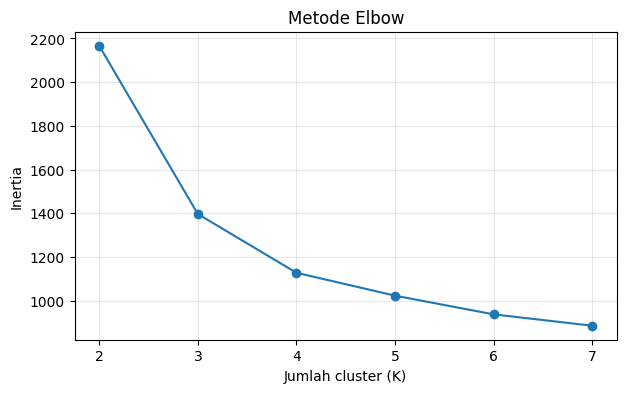

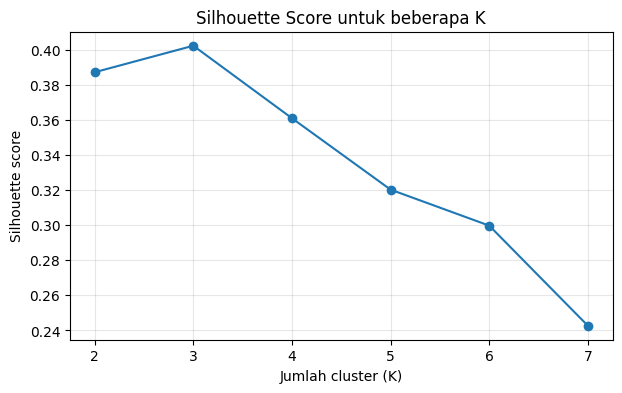

In [5]:
hasil_k = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = model.fit_predict(X_scaled)
    hasil_k.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X_scaled, label)
    })
hasil_k = pd.DataFrame(hasil_k)
display(hasil_k)

plt.figure(figsize=(7,4))
plt.plot(hasil_k['k'], hasil_k['inertia'], marker='o')
plt.title('Metode Elbow')
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Inertia')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7,4))
plt.plot(hasil_k['k'], hasil_k['silhouette'], marker='o')
plt.title('Silhouette Score untuk beberapa K')
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Silhouette score')
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print("Silhouette score untuk K", K, ":", round(silhouette_score(X_scaled, df['cluster']), 3))
print("Jumlah pelanggan per cluster:")
display(df['cluster'].value_counts().sort_index().rename('jumlah_pelanggan').to_frame())

Silhouette score untuk K 4 : 0.361
Jumlah pelanggan per cluster:


,jumlah_pelanggan
cluster,
0,151
1,152
2,164
3,133


,usia_tahun,pendapatan_tahunan_juta_rp,skor_belanja_1_100,transaksi_per_bulan,rata_rata_belanja_ribu_rp,lama_menjadi_pelanggan_bulan,jumlah_pelanggan
cluster,,,,,,,
0,42.68,9.83,77.78,17.72,412.85,46.68,151
1,51.55,6.03,36.60,6.87,160.46,60.91,152
2,25.37,4.56,28.06,4.82,121.92,11.35,164
3,31.86,7.21,47.11,11.29,232.11,23.93,133


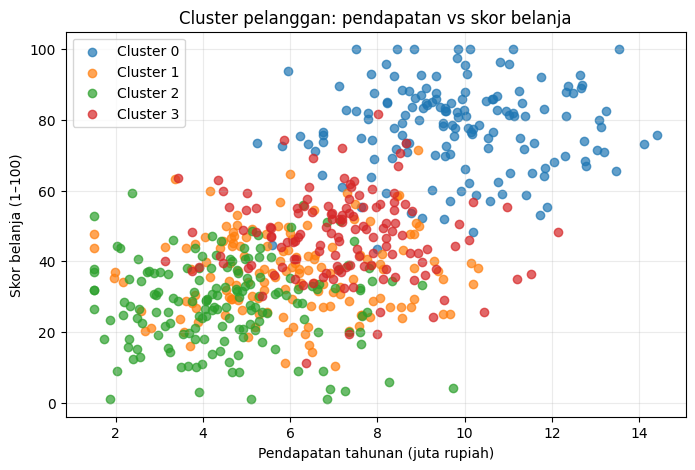

In [7]:
profil = df.groupby('cluster')[fitur].mean().round(2)
profil['jumlah_pelanggan'] = df.groupby('cluster').size()
display(profil)

# Visualisasi ringkas skor belanja dan pendapatan
plt.figure(figsize=(8,5))
for c in sorted(df['cluster'].unique()):
    bagian = df[df['cluster'] == c]
    plt.scatter(bagian['pendapatan_tahunan_juta_rp'], bagian['skor_belanja_1_100'], label=f'Cluster {c}', alpha=0.7)
plt.xlabel('Pendapatan tahunan (juta rupiah)')
plt.ylabel('Skor belanja (1–100)')
plt.title('Cluster pelanggan: pendapatan vs skor belanja')
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

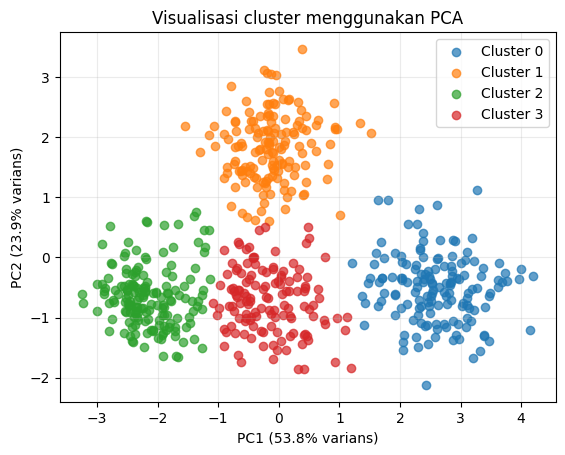

Total varians yang dijelaskan 2 komponen: 77.69 %


In [8]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
visual = pd.DataFrame({'PC1': X_2d[:,0], 'PC2': X_2d[:,1], 'cluster': df['cluster'].astype(str)})
for c in sorted(visual['cluster'].unique()):
    sub = visual[visual['cluster'] == c]
    plt.scatter(sub['PC1'], sub['PC2'], label=f'Cluster {c}', alpha=0.7)
plt.title('Visualisasi cluster menggunakan PCA')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)')
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()
print('Total varians yang dijelaskan 2 komponen:', round(pca.explained_variance_ratio_.sum()*100, 2), '%')

In [9]:
hasil = df.copy()
hasil.to_csv('hasil_segmentasi_pelanggan.csv', index=False)
profil.to_csv('profil_cluster.csv')
print('File berhasil disimpan: hasil_segmentasi_pelanggan.csv dan profil_cluster.csv')
files.download('hasil_segmentasi_pelanggan.csv')
files.download('profil_cluster.csv')

File berhasil disimpan: hasil_segmentasi_pelanggan.csv dan profil_cluster.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>